# IPL Data Analysis (2008–2024)

## 1. Overview

This project explores **Indian Premier League (IPL)** match and delivery data spanning 17 seasons (2008–2024).  
Using Python (pandas), SQLite, SciPy, matplotlib/seaborn, and Plotly it investigates team performance, toss dynamics,  
venue patterns, and individual player statistics — producing actionable insights for sports analytics.

It also exports analysis-ready tables to `powerbi/` so the same cleaned data can drive a Power BI dashboard.

**How to read this notebook:** cleaning decisions are checked immediately after they are applied. Sample-size rules and hypothesis tests sit next to the claim they support. Super-over balls (innings 3+) are dropped before player and venue-rate stats so career totals reflect regulation cricket.

## 2. Problem Statement

The IPL generates enormous amounts of match data across every season, but raw numbers alone don't reveal the deeper patterns behind team success, toss advantage, venue bias, or player consistency. The challenge is to clean, standardise, and interrogate this data rigorously — surfacing insights that are both analytically sound and statistically defensible.

## 3. Objectives

- **Which teams** have accumulated the most wins, and what is their win percentage across all seasons?
- **Does winning the toss** actually improve a team's chance of winning the match?
- **Does the toss decision** (bat vs. field) matter — and is that advantage statistically significant?
- **How many matches** were played per season, and which venues hosted the most games?
- **Who are the top run-scorers and wicket-takers** across all IPL seasons?
- **Which venues** produce the most sixes per match (all matches at the venue in the denominator, not only matches that had a six)?
- **Season-wise top scorer** using SQL window functions (RANK).
- **Does the field-first toss association hold at venue level**, or is it concentrated at a few grounds?

## 4. Dataset Description

| File | Source | Rows | Key Columns |
|------|--------|------|-------------|
| `matches.csv` | [Kaggle — IPL Complete Dataset (2008–2024)](https://www.kaggle.com/datasets/patrickb1912/ipl-complete-dataset-20082020) (Cricsheet) | 1,095 | id, season, city, date, venue, team1, team2, toss_winner, toss_decision, winner, result, result_margin |
| `deliveries.csv` | same | 260,920 | match_id, inning, batting_team, bowling_team, over, ball, batter, bowler, batsman_runs, is_wicket, dismissal_kind |

`matches.csv` covers one row per match; `deliveries.csv` covers one row per ball delivered.  
The two files join on `matches.id = deliveries.match_id` (verified 1:1 in the loading cell). Innings 3+ are super overs and are excluded from player and sixes-per-match stats.

## 5. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sqlite3
from scipy import stats

# ── Styling ────────────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.figsize'   : (13, 5),
    'axes.titlesize'   : 14,
    'axes.titleweight' : 'bold',
    'axes.labelsize'   : 11,
    'xtick.labelsize'  : 9,
    'ytick.labelsize'  : 9,
})

# Custom IPL colour palette (team colours inspired)
IPL_PALETTE = [
    '#1a6eb5', '#f5a623', '#0d7c4e', '#c0392b',
    '#8e44ad', '#2980b9', '#e67e22', '#27ae60',
    '#e74c3c', '#9b59b6', '#3498db', '#f39c12',
    '#1abc9c', '#d35400', '#2ecc71',
]

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:.2f}'.format)
print('Libraries loaded successfully.')

Libraries loaded successfully.


## 6. Data Loading

In [2]:
df         = pd.read_csv('matches.csv')
deliveries = pd.read_csv('deliveries.csv')

print('matches.csv shape  :', df.shape)
print('deliveries.csv shape:', deliveries.shape)

match_ids = set(df['id'])
ball_ids  = set(deliveries['match_id'])
assert match_ids == ball_ids, (
    f'Join is not 1:1 — {len(match_ids - ball_ids)} matches have no balls, '
    f'{len(ball_ids - match_ids)} delivery ids are missing from matches.'
)
print('Join check passed: every match has deliveries and every delivery belongs to a match.')

matches.csv shape  : (1095, 20)
deliveries.csv shape: (260920, 17)


## 7. Data Understanding

In [3]:
# First five rows — shows raw season format ('2007/08'), date as string,
# and team names that will need standardisation later.
df.head()

,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.00,223.00,20.00,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.00,241.00,20.00,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.00,130.00,20.00,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.00,166.00,20.00,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.00,111.00,20.00,N,NaN,BF Bowden,K Hariharan


In [4]:
# 1,095 matches x 20 columns; date is object (needs conversion),
# winner and city have small gaps -- to be handled per-column.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id               1095 non-null   int64  
 1   season           1095 non-null   str    
 2   city             1044 non-null   str    
 3   date             1095 non-null   str    
 4   match_type       1095 non-null   str    
 5   player_of_match  1090 non-null   str    
 6   venue            1095 non-null   str    
 7   team1            1095 non-null   str    
 8   team2            1095 non-null   str    
 9   toss_winner      1095 non-null   str    
 10  toss_decision    1095 non-null   str    
 11  winner           1090 non-null   str    
 12  result           1095 non-null   str    
 13  result_margin    1076 non-null   float64
 14  target_runs      1092 non-null   float64
 15  target_overs     1092 non-null   float64
 16  super_over       1095 non-null   str    
 17  method           21 non-n

In [5]:
# target_runs ranges 43-288 (median ~166), result_margin up to 146 --
# both confirm wide scoring variance across venues and seasons.
df.describe()

,id,result_margin,target_runs,target_overs
count,1095.00,1076.00,1092.00,1092.00
mean,904828.32,17.26,165.68,19.76
std,367740.24,21.79,33.43,1.58
min,335982.00,1.00,43.00,5.00
25%,548331.50,6.00,146.00,20.00
50%,980961.00,8.00,166.00,20.00
75%,1254062.50,20.00,187.00,20.00
max,1426312.00,146.00,288.00,20.00


In [6]:
# 19 unique team1 values before cleaning -- flags spelling drift and rebrands.
print('Unique teams (raw):', df['team1'].nunique())
print(df['team1'].value_counts())

Unique teams (raw): 19
team1
Royal Challengers Bangalore    135
Chennai Super Kings            128
Mumbai Indians                 123
Kolkata Knight Riders          121
Rajasthan Royals               101
Kings XI Punjab                 92
Sunrisers Hyderabad             86
Delhi Daredevils                85
Delhi Capitals                  41
Deccan Chargers                 39
Punjab Kings                    31
Pune Warriors                   23
Lucknow Super Giants            23
Gujarat Titans                  21
Gujarat Lions                   16
Royal Challengers Bengaluru      9
Kochi Tuskers Kerala             7
Rising Pune Supergiants          7
Rising Pune Supergiant           7
Name: count, dtype: int64


In [7]:
print('Missing values per column:')
print(df.isnull().sum())

Missing values per column:
id                    0
season                0
city                 51
date                  0
match_type            0
player_of_match       5
venue                 0
team1                 0
team2                 0
toss_winner           0
toss_decision         0
winner                5
result                0
result_margin        19
target_runs           3
target_overs          3
super_over            0
method             1074
umpire1               0
umpire2               0
dtype: int64


In [8]:
# deliveries.csv: 260,920 ball-level rows across 17 columns.
print(deliveries.shape)
print(deliveries.columns.tolist())
deliveries.head(3)

(260920, 17)
['match_id', 'inning', 'batting_team', 'bowling_team', 'over', 'ball', 'batter', 'bowler', 'non_striker', 'batsman_runs', 'extra_runs', 'total_runs', 'extras_type', 'is_wicket', 'player_dismissed', 'dismissal_kind', 'fielder']


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN


## 8. Data Cleaning

Each fix is documented with its reason below.

In [9]:
# Fix 1 -- date: convert from string to datetime64 so we can do time arithmetic.
df['date'] = pd.to_datetime(df['date'])
print(df['date'].dtype)

datetime64[us]


In [10]:
# Fix 2 -- season: original column contains strings like '2007/08'.
# Slicing the first 4 characters merges 2009 and 2010 into '2009' (bug).
# Deriving from date.dt.year correctly separates all 17 seasons.
df['season'] = df['date'].dt.year
print(df.groupby('season')['id'].count())

season
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
2024    71
Name: id, dtype: int64


In [11]:
# Fix 3 -- team name standardisation (matches.csv)
# Spelling drift merged  : 'Royal Challengers Bengaluru' -> 'Royal Challengers Bangalore'
#                          'Rising Pune Supergiants'     -> 'Rising Pune Supergiant'
# Genuine rebrands merged: 'Kings XI Punjab'  -> 'Punjab Kings'
#                          'Delhi Daredevils' -> 'Delhi Capitals'
# Kept separate          : 'Deccan Chargers' and 'Sunrisers Hyderabad'
#                          (different ownership, not just a rename)

name_map = {
    'Royal Challengers Bengaluru': 'Royal Challengers Bangalore',
    'Rising Pune Supergiants':     'Rising Pune Supergiant',
    'Kings XI Punjab':             'Punjab Kings',
    'Delhi Daredevils':            'Delhi Capitals',
}

for col in ['team1', 'team2', 'toss_winner', 'winner']:
    df[col] = df[col].replace(name_map)

print('Unique teams after cleaning:', pd.concat([df['team1'], df['team2']]).nunique())
print(df['team1'].value_counts())

Unique teams after cleaning: 15
team1
Royal Challengers Bangalore    144
Chennai Super Kings            128
Delhi Capitals                 126
Punjab Kings                   123
Mumbai Indians                 123
Kolkata Knight Riders          121
Rajasthan Royals               101
Sunrisers Hyderabad             86
Deccan Chargers                 39
Pune Warriors                   23
Lucknow Super Giants            23
Gujarat Titans                  21
Gujarat Lions                   16
Rising Pune Supergiant          14
Kochi Tuskers Kerala             7
Name: count, dtype: int64


In [12]:
# Fix 4 -- venue name standardisation
# Step A: strip city suffixes appended with commas (e.g., 'Wankhede Stadium, Mumbai')
df['venue'] = df['venue'].str.split(',').str[0]

# Step B: normalise renamed grounds
venue_map = {
    'M.Chinnaswamy Stadium':                      'M Chinnaswamy Stadium',
    'Feroz Shah Kotla':                           'Arun Jaitley Stadium',
    'Feroz Shah Kotla Ground':                    'Arun Jaitley Stadium',
    'Punjab Cricket Association Stadium':          'Punjab Cricket Association IS Bindra Stadium',
    'Sardar Patel Stadium':                       'Narendra Modi Stadium',
    'Sheikh Zayed Stadium':                       'Zayed Cricket Stadium',  # Abu Dhabi rename
    'Subrata Roy Sahara Stadium':                 'Maharashtra Cricket Association Stadium',  # Pune rename
}
df['venue'] = df['venue'].replace(venue_map)

print('Unique venues after cleaning:', df['venue'].nunique())
print(df['venue'].value_counts().head(10))

Unique venues after cleaning: 38
venue
Wankhede Stadium                                118
M Chinnaswamy Stadium                            94
Eden Gardens                                     93
Arun Jaitley Stadium                             90
MA Chidambaram Stadium                           85
Rajiv Gandhi International Stadium               77
Punjab Cricket Association IS Bindra Stadium     61
Sawai Mansingh Stadium                           57
Dubai International Cricket Stadium              46
Dr DY Patil Sports Academy                       37
Name: count, dtype: int64


In [13]:
# Fix 5 -- missing values (handled per-column, NOT a blanket dropna)

# city: 51 nulls are UAE venues (Sharjah, Dubai) -- fill from venue name.
df.loc[df['venue'] == 'Dubai International Cricket Stadium', 'city'] = 'Dubai'
df.loc[df['venue'] == 'Sharjah Cricket Stadium',            'city'] = 'Sharjah'

# winner: 5 nulls are 'no result' matches -- fill with sentinel string.
df['winner'] = df['winner'].fillna('No Result')

# method: 21 non-null values are D/L matches; rest are normal -- fill with 'Normal'.
df['method'] = df['method'].fillna('Normal')

# result_margin: 19 nulls are ties / no-result -- filled with -1 as a placeholder.
# NOTE: -1 is not a real margin; exclude it from averages (Section 14 turns it back into NULL for Power BI).
df['result_margin'] = df['result_margin'].fillna(-1)

# target_runs / target_overs: 3 nulls are no-result matches -- same -1 placeholder.
df[['target_runs', 'target_overs']] = df[['target_runs', 'target_overs']].fillna(-1)

# player_of_match: 5 nulls remain -- left as NaN (no sensible imputation).

print('Remaining nulls per column:')
print(df.isnull().sum())
print('\nDuplicates:', df.duplicated().sum())

Remaining nulls per column:
id                 0
season             0
city               0
date               0
match_type         0
player_of_match    5
venue              0
team1              0
team2              0
toss_winner        0
toss_decision      0
winner             0
result             0
result_margin      0
target_runs        0
target_overs       0
super_over         0
method             0
umpire1            0
umpire2            0
dtype: int64

Duplicates: 0


In [14]:
# Fix 6 -- deliveries.csv needs the same team-name cleaning independently.
# Cleaning matches.csv does NOT propagate to deliveries.csv (two separate files).
for col in ['batting_team', 'bowling_team']:
    deliveries[col] = deliveries[col].replace(name_map)

print('Deliveries team names cleaned.')
print('Deliveries missing values:')
print(deliveries.isnull().sum()[deliveries.isnull().sum() > 0])

# Super overs (innings 3+) are not regulation cricket. Leave them out of career
# batting/bowling totals and venue scoring rates so the numbers match scorecards,
# not the 14 matches that went to a super over.
extra_innings = int((deliveries['inning'] > 2).sum())
print(f'\nSuper-over / extra-innings balls excluded: {extra_innings:,}')
deliveries = deliveries[deliveries['inning'] <= 2].copy()
print('Regulation deliveries:', deliveries.shape)

Deliveries team names cleaned.
Deliveries missing values:


extras_type         246795
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64


## 9. Exploratory Data Analysis

Organised by theme: **Teams → Toss → Matches → Players**

### 9.1 Teams

In [15]:
# Q1: How many distinct teams have participated across all seasons?
all_teams = pd.concat([df['team1'], df['team2']])
print('Total distinct teams:', all_teams.nunique())

Total distinct teams: 15


In [16]:
# Q2: Which team has won the most matches?
valid_matches = df[df['winner'] != 'No Result']
wins = valid_matches['winner'].value_counts()
print(wins)
# Mumbai Indians lead in raw wins (144), followed by Chennai Super Kings (138).

winner
Mumbai Indians                 144
Chennai Super Kings            138
Kolkata Knight Riders          131
Royal Challengers Bangalore    123
Delhi Capitals                 115
Rajasthan Royals               112
Punjab Kings                   112
Sunrisers Hyderabad             88
Deccan Chargers                 29
Gujarat Titans                  28
Lucknow Super Giants            24
Rising Pune Supergiant          15
Gujarat Lions                   13
Pune Warriors                   12
Kochi Tuskers Kerala             6
Name: count, dtype: int64


In [17]:
# Q3: Which team has the best win percentage?
total_matches = pd.concat([df['team1'], df['team2']]).value_counts()
win_pct = (wins / total_matches * 100).sort_values(ascending=False)
print(win_pct.round(2))
# Gujarat Titans lead at ~62% but have played far fewer seasons.
# CSK rank 2nd at ~58% -- compressed into fewer active seasons due to the 2016-17 suspension.

winner
Gujarat Titans                62.22
Chennai Super Kings           57.98
Mumbai Indians                55.17
Lucknow Super Giants          54.55
Kolkata Knight Riders         52.19
Rajasthan Royals              50.68
Rising Pune Supergiant        50.00
Sunrisers Hyderabad           48.35
Royal Challengers Bangalore   48.24
Delhi Capitals                45.63
Punjab Kings                  45.53
Gujarat Lions                 43.33
Kochi Tuskers Kerala          42.86
Deccan Chargers               38.67
Pune Warriors                 26.09
Name: count, dtype: float64


### 9.2 Toss

In [18]:
# Q4: Does winning the toss help win the match?
valid_matches = df[df['winner'] != 'No Result'].copy()
valid_matches['toss_win_match_win'] = (valid_matches['toss_winner'] == valid_matches['winner'])
toss_overall_rate = valid_matches['toss_win_match_win'].mean() * 100
print(f'Toss winner also wins match: {toss_overall_rate:.1f}% of the time')
# ~50.8% -- barely above chance; winning the toss alone is not a strong predictor.

Toss winner also wins match: 50.8% of the time


In [19]:
# Q5: What decision is most common after winning the toss?
print(df['toss_decision'].value_counts())
# 'field' chosen ~64% of the time, suggesting captains broadly prefer chasing.

toss_decision
field    704
bat      391
Name: count, dtype: int64


In [20]:
# Q6: Does the toss decision (bat / field) affect win rate for the toss winner?
decision_win_rate = valid_matches.groupby('toss_decision')['toss_win_match_win'].mean()
for decision, rate in decision_win_rate.items():
    print(f'{decision:<6}: {rate * 100:.1f}% of toss winners went on to win')
# Toss winners who chose to FIELD won ~53.9% of those matches;
# those who chose to BAT won only ~45.4% -- tested for significance in Section 11.

bat   : 45.4% of toss winners went on to win
field : 53.9% of toss winners went on to win


### 9.3 Matches

In [21]:
# Q7: How many matches were played each season?
season_counts = df.groupby('season')['id'].count()
print(season_counts)
# Seasons 2011-2013 had the most matches (73-76), reflecting expansion to 9-10 teams.

season
2008    58
2009    57
2010    60
2011    73
2012    74
2013    76
2014    60
2015    59
2016    60
2017    59
2018    60
2019    60
2020    60
2021    60
2022    74
2023    74
2024    71
Name: id, dtype: int64


In [22]:
# Q8: Which venues hosted the most matches?
print(df['venue'].value_counts().head(10))
# Wankhede (Mumbai, 118), M Chinnaswamy (Bangalore, 94), and Eden Gardens (Kolkata, 93)
# are the three most frequently used grounds.

venue
Wankhede Stadium                                118
M Chinnaswamy Stadium                            94
Eden Gardens                                     93
Arun Jaitley Stadium                             90
MA Chidambaram Stadium                           85
Rajiv Gandhi International Stadium               77
Punjab Cricket Association IS Bindra Stadium     61
Sawai Mansingh Stadium                           57
Dubai International Cricket Stadium              46
Dr DY Patil Sports Academy                       37
Name: count, dtype: int64


### 9.4 Players

In [23]:
# Q9: Top 10 run-scorers across all IPL seasons
runs = deliveries.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False)
print(runs.head(10))
# V Kohli leads with 8,014 runs -- nearly 1,250 more than 2nd-placed S Dhawan.

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
Name: batsman_runs, dtype: int64


In [24]:
# Q10: Top 10 batters by strike rate (minimum 1,000 balls faced)
legal_del = deliveries[deliveries['extras_type'] != 'wides']
bat_stats = legal_del.groupby('batter').agg(
    total_runs=('batsman_runs', 'sum'),
    balls_faced=('batsman_runs', 'count')
)
bat_stats['strike_rate'] = bat_stats['total_runs'] / bat_stats['balls_faced'] * 100
qualified = bat_stats[bat_stats['balls_faced'] >= 1000].sort_values('strike_rate', ascending=False)
print(qualified.head(10).round(2))
# AD Russell tops at ~174.8 SR -- among the most destructive hitters in IPL history.

                total_runs  balls_faced  strike_rate
batter                                              
AD Russell            2488         1423       174.84
N Pooran              1769         1092       162.00
GJ Maxwell            2772         1769       156.70
V Sehwag              2728         1755       155.44
AB de Villiers        5181         3411       151.89
YBK Jaiswal           1607         1067       150.61
CH Gayle              4997         3346       149.34
RR Pant               3297         2215       148.85
KA Pollard            3437         2329       147.57
PP Shaw               1892         1283       147.47


In [25]:
# Q11: Top 10 wicket-takers (bowler credit only -- excludes run-outs, retired hurt, etc.)
no_bowler_credit = ['run out', 'retired hurt', 'obstructing the field', 'retired out']
bowler_wkts = deliveries[
    (deliveries['is_wicket'] == 1) &
    (~deliveries['dismissal_kind'].isin(no_bowler_credit))
]
wickets = bowler_wkts.groupby('bowler')['is_wicket'].sum().sort_values(ascending=False)
print(wickets.head(10))
# YS Chahal leads with 205 wickets, ahead of PP Chawla (192) and DJ Bravo (183).

bowler
YS Chahal     205
PP Chawla     192
DJ Bravo      183
B Kumar       181
SP Narine     180
R Ashwin      180
A Mishra      174
SL Malinga    170
JJ Bumrah     168
RA Jadeja     160
Name: is_wicket, dtype: int64


## 10. SQL Analysis

Data is loaded into a local SQLite database for structured querying using CTEs and window functions.

In [26]:
conn = sqlite3.connect('ipl.db')
df.to_sql('matches',    conn, if_exists='replace', index=False)
deliveries.to_sql('deliveries', conn, if_exists='replace', index=False)
print('Tables written to ipl.db')

Tables written to ipl.db


In [27]:
# SQL Q1: Top 10 all-time run-scorers
query = """
SELECT batter, SUM(batsman_runs) AS total_runs
FROM   deliveries
GROUP  BY batter
ORDER  BY total_runs DESC
LIMIT  10
"""
pd.read_sql(query, conn)

,batter,total_runs
0,V Kohli,8014
1,S Dhawan,6769
2,RG Sharma,6630
3,DA Warner,6567
4,SK Raina,5536
5,MS Dhoni,5243
6,AB de Villiers,5181
7,CH Gayle,4997
8,RV Uthappa,4954
9,KD Karthik,4843


In [28]:
# SQL Q2: Win rate by toss decision using CASE / AVG
query = """
SELECT
    toss_decision,
    ROUND(AVG(CASE WHEN toss_winner = winner THEN 1 ELSE 0 END), 3) AS win_rate
FROM  matches
WHERE winner != 'No Result'
GROUP BY toss_decision
"""
pd.read_sql(query, conn)

,toss_decision,win_rate
0,bat,0.45
1,field,0.54


In [29]:
# SQL Q3: Venues with the highest sixes per match (JOIN + HAVING, min 20 matches)
query = """
SELECT
    m.venue,
    SUM(CASE WHEN d.batsman_runs = 6 THEN 1 ELSE 0 END) AS six_count,
    COUNT(DISTINCT m.id)                                AS matches_played,
    ROUND(
        CAST(SUM(CASE WHEN d.batsman_runs = 6 THEN 1 ELSE 0 END) AS FLOAT)
        / COUNT(DISTINCT m.id), 2
    )                                                   AS six_per_match
FROM  matches m
LEFT JOIN deliveries d ON d.match_id = m.id
GROUP BY m.venue
HAVING COUNT(DISTINCT m.id) > 20
ORDER BY six_per_match DESC
LIMIT 10
"""
# Start from matches (not from six-only balls) so venues with quiet games still
# count those matches in the denominator.
pd.read_sql(query, conn)

,venue,six_count,matches_played,six_per_match
0,M Chinnaswamy Stadium,1402,94,14.91
1,Sharjah Cricket Stadium,394,28,14.07
2,Narendra Modi Stadium,506,36,14.06
3,Wankhede Stadium,1611,118,13.65
4,Maharashtra Cricket Association Stadium,464,35,13.26
5,Eden Gardens,1183,93,12.72
6,Arun Jaitley Stadium,1133,90,12.59
7,Dr DY Patil Sports Academy,458,37,12.38
8,Brabourne Stadium,333,27,12.33
9,Rajiv Gandhi International Stadium,877,77,11.39


In [30]:
# SQL Q4: Season-wise top run-scorer using CTE + RANK() window function
query = """
WITH season_runs AS (
    SELECT
        m.season,
        d.batter,
        SUM(d.batsman_runs) AS total_runs
    FROM  deliveries d
    JOIN  matches    m ON d.match_id = m.id
    GROUP BY m.season, d.batter
)
SELECT season, batter, total_runs,
       RANK() OVER (PARTITION BY season ORDER BY total_runs DESC) AS season_rank
FROM   season_runs
"""
result = pd.read_sql(query, conn)
print(result[result['season_rank'] == 1].to_string(index=False))

 season        batter  total_runs  season_rank
   2008      SE Marsh         616            1
   2009     ML Hayden         572            1
   2010  SR Tendulkar         618            1
   2011      CH Gayle         608            1
   2012      CH Gayle         733            1
   2013    MEK Hussey         733            1
   2014    RV Uthappa         660            1
   2015     DA Warner         562            1
   2016       V Kohli         973            1
   2017     DA Warner         641            1
   2018 KS Williamson         735            1
   2019     DA Warner         692            1
   2020      KL Rahul         676            1
   2021    RD Gaikwad         635            1
   2022    JC Buttler         863            1
   2023  Shubman Gill         890            1
   2024       V Kohli         741            1


In [31]:
# SQL Q5: Teams with the highest average run margin in wins (batting first wins)
query = """
SELECT winner,
       COUNT(*)                        AS wins_by_runs,
       ROUND(AVG(result_margin), 1)    AS avg_margin
FROM  matches
WHERE result = 'runs' AND winner != 'No Result'
GROUP BY winner
HAVING COUNT(*) >= 10
ORDER BY avg_margin DESC
LIMIT 8
"""
pd.read_sql(query, conn)

,winner,wins_by_runs,avg_margin
0,Chennai Super Kings,71,34.90
1,Royal Challengers Bangalore,57,34.50
2,Gujarat Titans,11,34.20
3,Kolkata Knight Riders,54,33.60
4,Mumbai Indians,71,33.00
5,Rajasthan Royals,43,30.80
6,Delhi Capitals,46,25.60
7,Sunrisers Hyderabad,44,24.80


## 11. Statistical Testing

We use a **chi-square test of independence** to determine whether toss outcome and match result are statistically related.  
H₀: Winning the toss and winning the match are **independent** (toss does not help).  
H₁: There is a significant association between toss win and match win.

In [32]:
from scipy.stats import chi2_contingency

vm = df[df['winner'] != 'No Result'].copy()

# Teams are labelled team1/team2 arbitrarily, so the 2x2 table asks:
# "Is 'team1 won the toss' associated with 'team1 won the match'?"
vm['team1_won']     = (vm['winner'] == vm['team1']).astype(int)
vm['toss_to_team1'] = (vm['toss_winner'] == vm['team1']).astype(int)

ct = pd.crosstab(vm['toss_to_team1'], vm['team1_won'],
                 rownames=['Toss won by team1'], colnames=['Match won by team1'])
print('Contingency Table:')
print(ct)

chi2, p_value, dof, expected = chi2_contingency(ct)
print(f'\nChi-square statistic : {chi2:.4f}')
print(f'p-value              : {p_value:.4f}')
print(f'Degrees of freedom   : {dof}')
alpha = 0.05
if p_value < alpha:
    print(f'\nResult: REJECT H0 (p={p_value:.4f} < {alpha})')
    print('Toss outcome IS statistically associated with match outcome.')
else:
    print(f'\nResult: FAIL TO REJECT H0 (p={p_value:.4f} >= {alpha})')
    print('Toss outcome is NOT a statistically significant predictor of match outcome.')

Contingency Table:
Match won by team1    0    1
Toss won by team1           
0                   333  334
1                   202  221

Chi-square statistic : 0.4051
p-value              : 0.5245
Degrees of freedom   : 1

Result: FAIL TO REJECT H0 (p=0.5245 >= 0.05)
Toss outcome is NOT a statistically significant predictor of match outcome.


### Does the toss *decision* matter?

The test above asks whether **winning the toss** helps. A different question is whether, **among toss winners**, choosing to *field* instead of *bat* changes the chance of winning the match.  
H₀: win rate is the same after choosing to bat or to field.  
H₁: the two win rates differ.

This matters because a blended average (toss winners overall win ~50.8%) can hide a real split between sub-groups.

In [33]:
# Test 2 -- among toss winners, does bat-vs-field change the chance of winning the match?
vm['toss_winner_won'] = (vm['toss_winner'] == vm['winner']).astype(int)

ct2 = pd.crosstab(vm['toss_decision'], vm['toss_winner_won'],
                  rownames=['Toss decision'], colnames=['Toss winner won match'])
print('Contingency Table:')
print(ct2)

chi2_d, p_decision, dof_d, _ = chi2_contingency(ct2)

rates = vm.groupby('toss_decision')['toss_winner_won'].agg(rate='mean', n='count')
diff  = rates.loc['field', 'rate'] - rates.loc['bat', 'rate']
se    = np.sqrt((rates['rate'] * (1 - rates['rate']) / rates['n']).sum())

print(f"\nWin rate after choosing to FIELD : {rates.loc['field', 'rate'] * 100:.1f}%  (n={rates.loc['field', 'n']})")
print(f"Win rate after choosing to BAT   : {rates.loc['bat', 'rate'] * 100:.1f}%  (n={rates.loc['bat', 'n']})")
print(f"Difference (field - bat)         : {diff * 100:+.1f} percentage points "
      f"(95% CI {100 * (diff - 1.96 * se):.1f} to {100 * (diff + 1.96 * se):.1f})")
print(f'Chi-square = {chi2_d:.3f},  p-value = {p_decision:.4f}')
print('Result:', 'SIGNIFICANT at the 5% level' if p_decision < 0.05 else 'not significant at the 5% level')
print('\nCaution: this is observational. Captains choose to field in conditions they expect to favour a chase,')
print('so the gap shows an association with the decision, not proof that fielding causes wins.')

Contingency Table:
Toss winner won match    0    1
Toss decision                  
bat                    213  177
field                  323  377

Win rate after choosing to FIELD : 53.9%  (n=700)
Win rate after choosing to BAT   : 45.4%  (n=390)
Difference (field - bat)         : +8.5 percentage points (95% CI 2.3 to 14.6)
Chi-square = 6.859,  p-value = 0.0088
Result: SIGNIFICANT at the 5% level

Caution: this is observational. Captains choose to field in conditions they expect to favour a chase,
so the gap shows an association with the decision, not proof that fielding causes wins.


## 12. Visualisations

All charts use a consistent IPL-inspired colour palette with clear titles, axis labels, and value annotations.

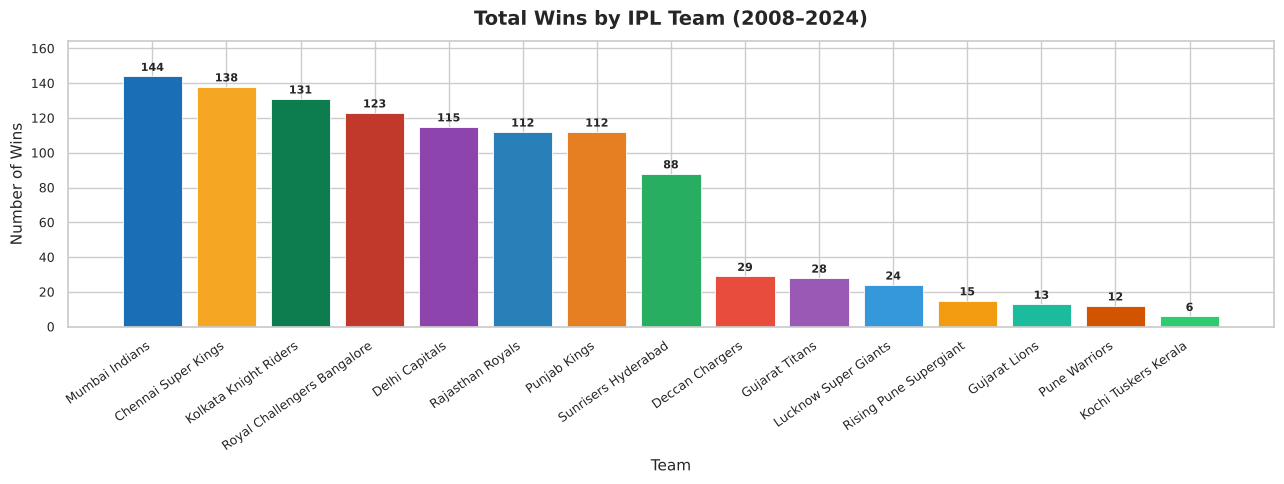

In [34]:
# Chart 1 — Total wins by team (bar chart)
fig, ax = plt.subplots(figsize=(13, 5))
sorted_wins = wins.sort_values(ascending=False)
bars = ax.bar(sorted_wins.index, sorted_wins.values,
              color=IPL_PALETTE[:len(sorted_wins)], edgecolor='white', linewidth=0.6)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1.5,
            str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=8, fontweight='bold')
ax.set_title('Total Wins by IPL Team (2008–2024)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Team')
ax.set_ylabel('Number of Wins')
ax.set_ylim(0, sorted_wins.max() + 20)
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

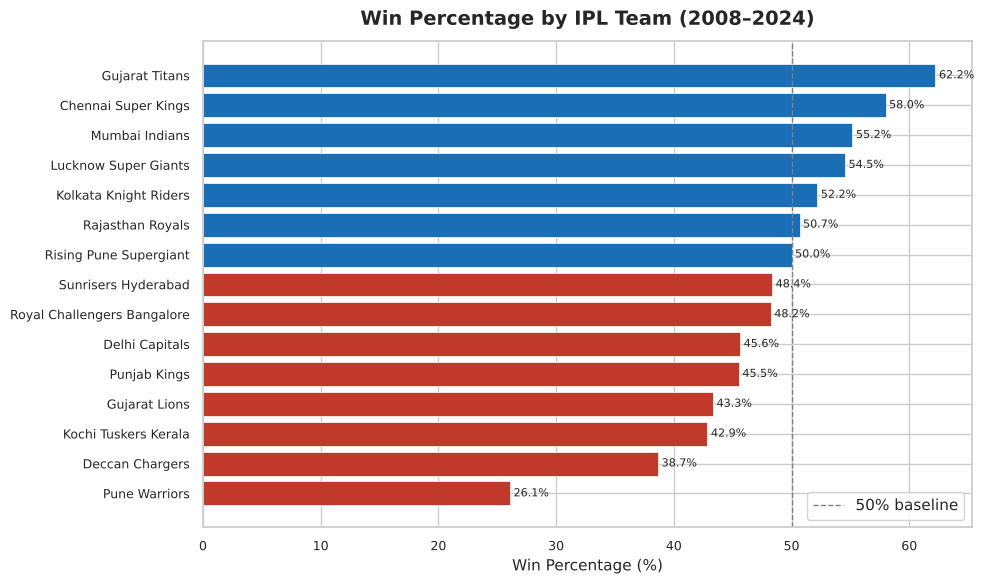

In [35]:
# Chart 2 — Win percentage by team (horizontal bar)
fig, ax = plt.subplots(figsize=(10, 6))
wp = win_pct.sort_values()
colors = ['#1a6eb5' if v >= 50 else '#c0392b' for v in wp.values]
bars = ax.barh(wp.index, wp.values, color=colors, edgecolor='white', linewidth=0.5)
for bar in bars:
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():.1f}%', va='center', fontsize=8)
ax.axvline(50, color='grey', linestyle='--', linewidth=1, label='50% baseline')
ax.set_title('Win Percentage by IPL Team (2008–2024)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Win Percentage (%)')
ax.legend()
plt.tight_layout()
plt.show()

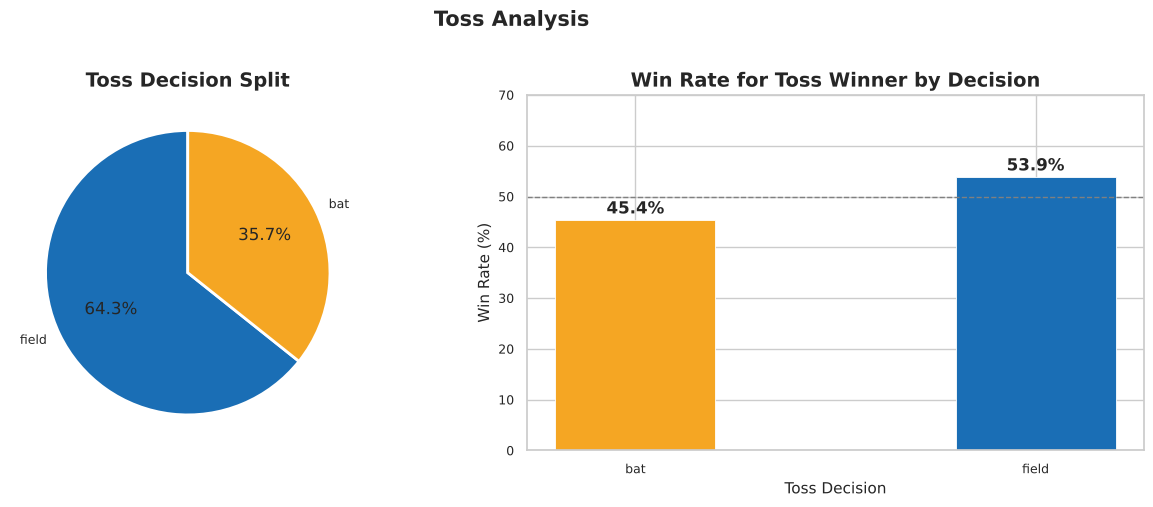

In [36]:
# Chart 3 — Toss decision distribution (pie)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Pie: decision split
dec_counts = df['toss_decision'].value_counts()
axes[0].pie(dec_counts.values, labels=dec_counts.index,
            autopct='%1.1f%%', colors=['#1a6eb5', '#f5a623'],
            startangle=90, wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[0].set_title('Toss Decision Split', fontweight='bold')

# Bar: win rate by decision
dr = valid_matches.groupby('toss_decision')['toss_win_match_win'].mean() * 100
bar_colors = ['#f5a623', '#1a6eb5']
bars = axes[1].bar(dr.index, dr.values, color=bar_colors, width=0.4,
                   edgecolor='white', linewidth=0.6)
for bar in bars:
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.5,
                 f'{bar.get_height():.1f}%',
                 ha='center', va='bottom', fontweight='bold')
axes[1].axhline(50, color='grey', linestyle='--', linewidth=1)
axes[1].set_ylim(0, 70)
axes[1].set_title('Win Rate for Toss Winner by Decision', fontweight='bold')
axes[1].set_ylabel('Win Rate (%)')
axes[1].set_xlabel('Toss Decision')

plt.suptitle('Toss Analysis', fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

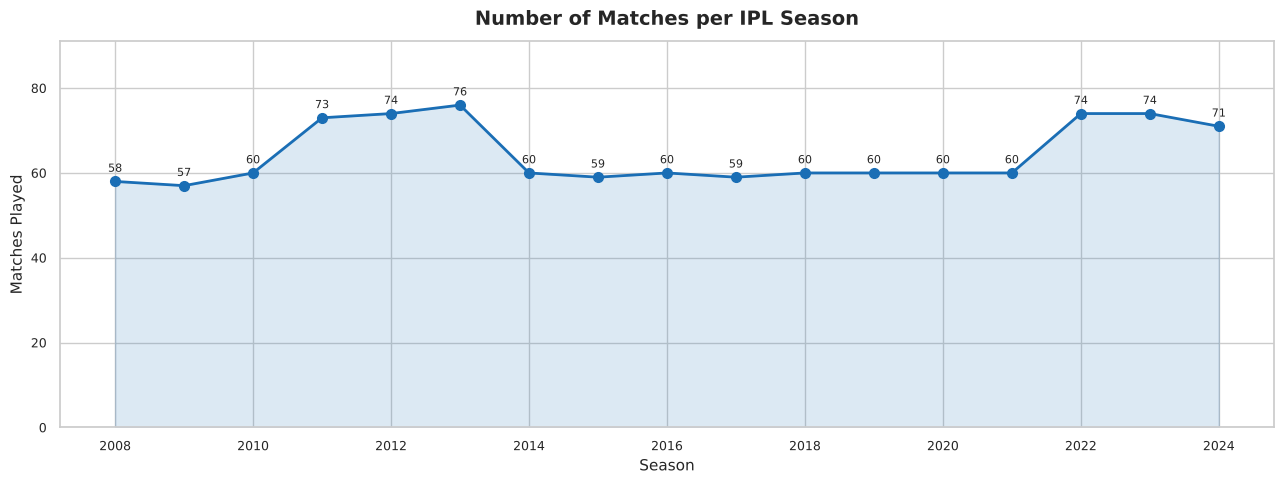

In [37]:
# Chart 4 — Matches per season (line + area)
fig, ax = plt.subplots(figsize=(13, 5))
sc = df.groupby('season')['id'].count()
ax.fill_between(sc.index, sc.values, alpha=0.15, color='#1a6eb5')
ax.plot(sc.index, sc.values, marker='o', color='#1a6eb5',
        linewidth=2, markersize=7)
for x, y in zip(sc.index, sc.values):
    ax.annotate(str(y), (x, y), textcoords='offset points',
                xytext=(0, 7), ha='center', fontsize=8)
ax.set_title('Number of Matches per IPL Season', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Season')
ax.set_ylabel('Matches Played')
ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
ax.set_ylim(0, sc.max() + 15)
plt.tight_layout()
plt.show()

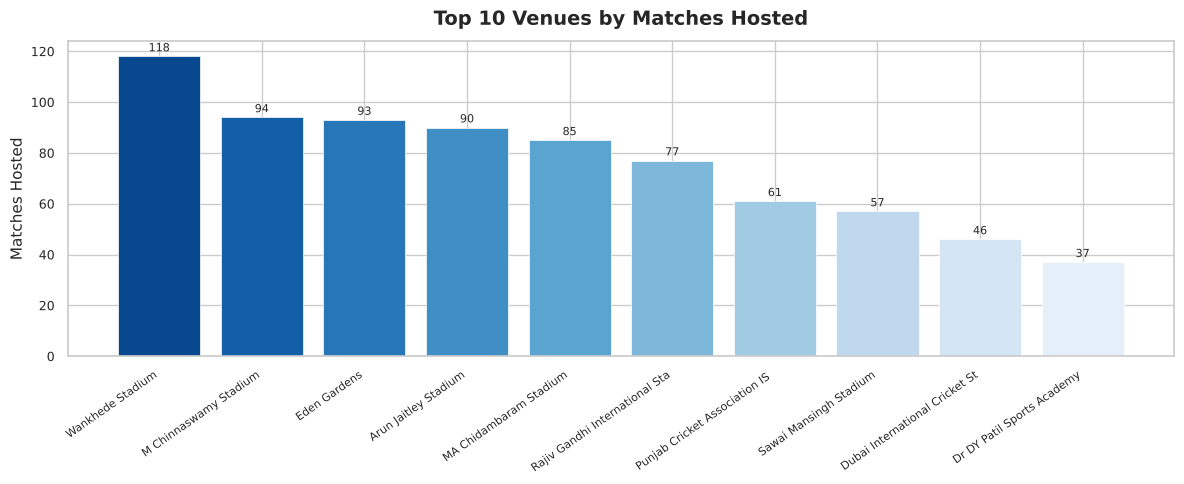

In [38]:
# Chart 5 — Top 10 venues by matches hosted
fig, ax = plt.subplots(figsize=(12, 5))
top_venues = df['venue'].value_counts().head(10)
bars = ax.bar(range(len(top_venues)), top_venues.values,
              color=sns.color_palette('Blues_r', len(top_venues)),
              edgecolor='white', linewidth=0.5)
for i, bar in enumerate(bars):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=8)
ax.set_xticks(range(len(top_venues)))
ax.set_xticklabels([v[:30] for v in top_venues.index], rotation=35, ha='right', fontsize=8)
ax.set_title('Top 10 Venues by Matches Hosted', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Matches Hosted')
plt.tight_layout()
plt.show()

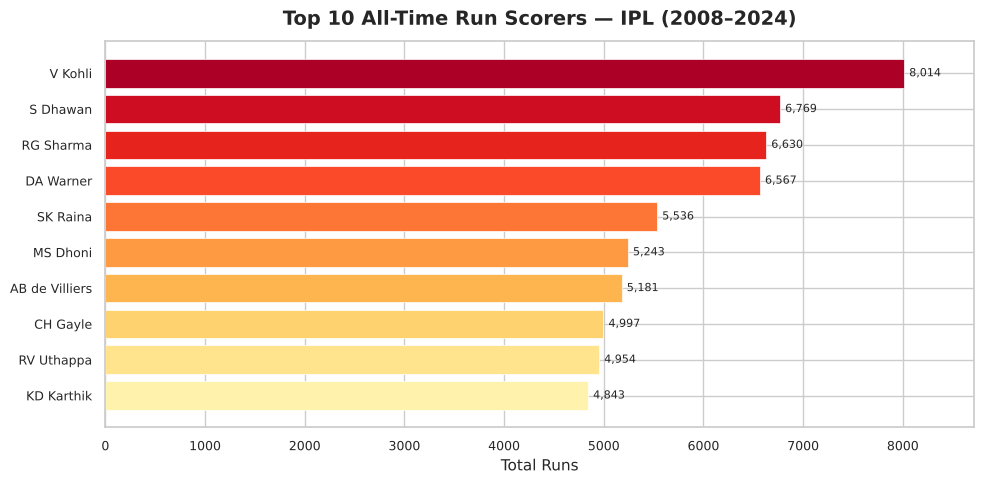

In [39]:
# Chart 6 — Top 10 run-scorers (horizontal bar)
fig, ax = plt.subplots(figsize=(10, 5))
top_runs = runs.head(10).sort_values()
gradient = sns.color_palette('YlOrRd', len(top_runs))
bars = ax.barh(top_runs.index, top_runs.values,
               color=gradient, edgecolor='white', linewidth=0.5)
for bar in bars:
    ax.text(bar.get_width() + 50, bar.get_y() + bar.get_height() / 2,
            f'{int(bar.get_width()):,}',
            va='center', fontsize=8)
ax.set_title('Top 10 All-Time Run Scorers — IPL (2008–2024)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Total Runs')
ax.set_xlim(0, top_runs.max() + 700)
plt.tight_layout()
plt.show()

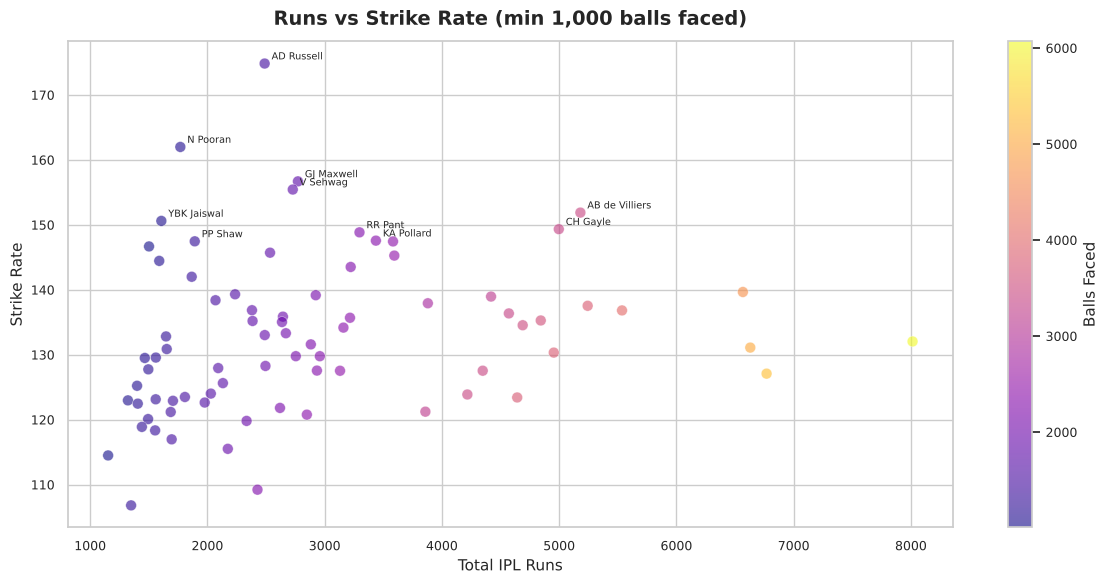

In [40]:
# Chart 7 — Strike rate vs total runs scatter (qualified batters >= 1000 balls)
fig, ax = plt.subplots(figsize=(12, 6))
q = qualified.reset_index()
scatter = ax.scatter(q['total_runs'], q['strike_rate'],
                     alpha=0.6, s=60, c=q['balls_faced'],
                     cmap='plasma', edgecolors='white', linewidth=0.4)
plt.colorbar(scatter, ax=ax, label='Balls Faced')
# Label top 10 by SR
top_sr = q.nlargest(10, 'strike_rate')
for _, row in top_sr.iterrows():
    ax.annotate(row['batter'], (row['total_runs'], row['strike_rate']),
                textcoords='offset points', xytext=(5, 3), fontsize=7)
ax.set_title('Runs vs Strike Rate (min 1,000 balls faced)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Total IPL Runs')
ax.set_ylabel('Strike Rate')
plt.tight_layout()
plt.show()

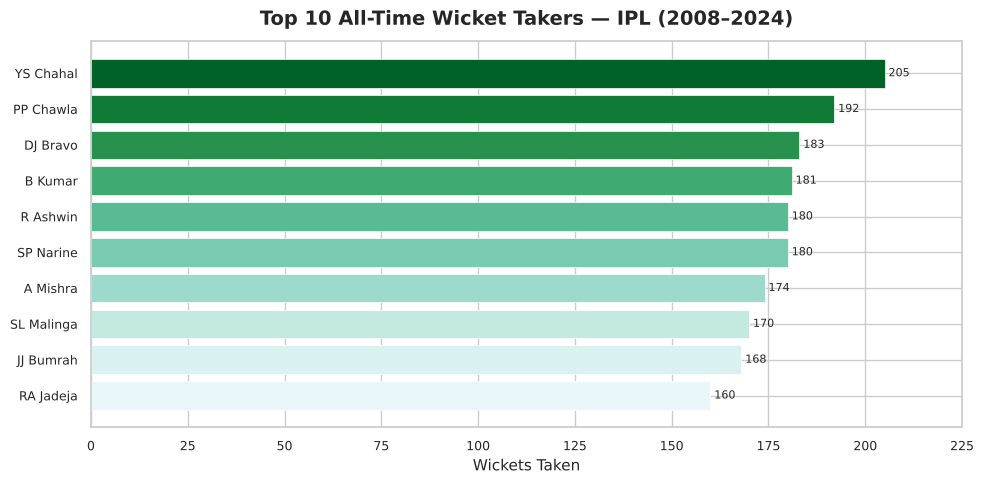

In [41]:
# Chart 8 — Top 10 wicket-takers
fig, ax = plt.subplots(figsize=(10, 5))
top_wkts = wickets.head(10).sort_values()
gradient = sns.color_palette('BuGn', len(top_wkts))
bars = ax.barh(top_wkts.index, top_wkts.values,
               color=gradient, edgecolor='white', linewidth=0.5)
for bar in bars:
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            str(int(bar.get_width())),
            va='center', fontsize=8)
ax.set_title('Top 10 All-Time Wicket Takers — IPL (2008–2024)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Wickets Taken')
ax.set_xlim(0, top_wkts.max() + 20)
plt.tight_layout()
plt.show()

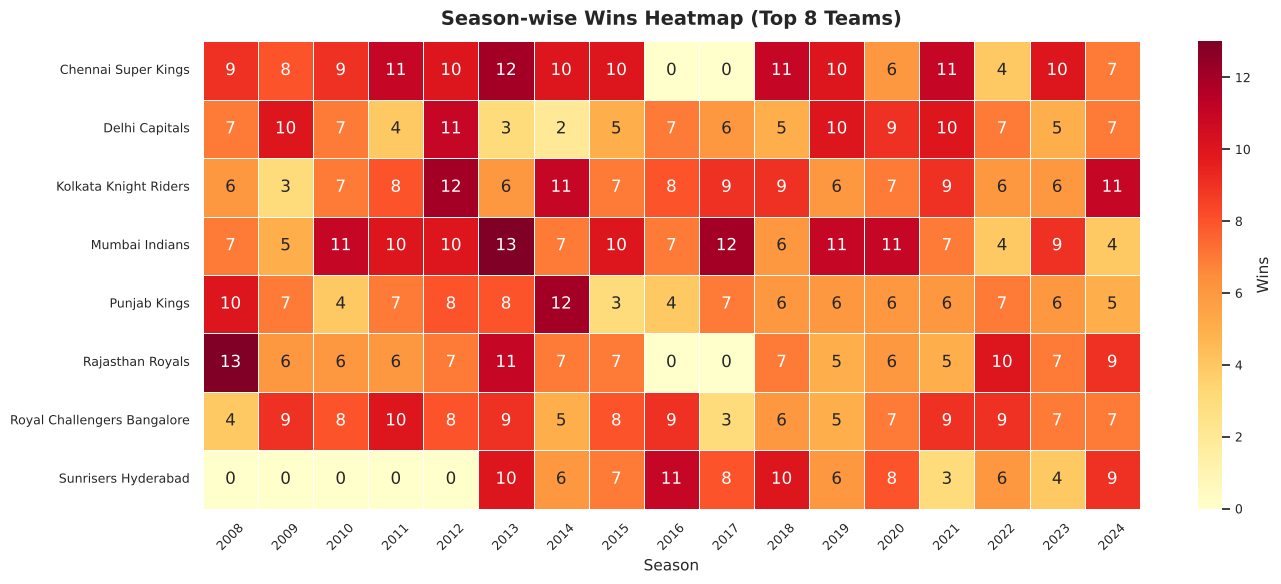

In [42]:
# Chart 9 — Season-wise wins heatmap (teams x seasons)
major_teams = [
    'Mumbai Indians', 'Chennai Super Kings', 'Kolkata Knight Riders',
    'Royal Challengers Bangalore', 'Delhi Capitals', 'Rajasthan Royals',
    'Punjab Kings', 'Sunrisers Hyderabad'
]
season_team_wins = (
    valid_matches[valid_matches['winner'].isin(major_teams)]
    .groupby(['season', 'winner'])['id'].count()
    .unstack('winner')
    .fillna(0)
)
fig, ax = plt.subplots(figsize=(14, 6))
sns.heatmap(season_team_wins.T, annot=True, fmt='.0f',
            cmap='YlOrRd', linewidths=0.5, linecolor='white',
            ax=ax, cbar_kws={'label': 'Wins'})
ax.set_title('Season-wise Wins Heatmap (Top 8 Teams)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Season')
ax.set_ylabel('')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

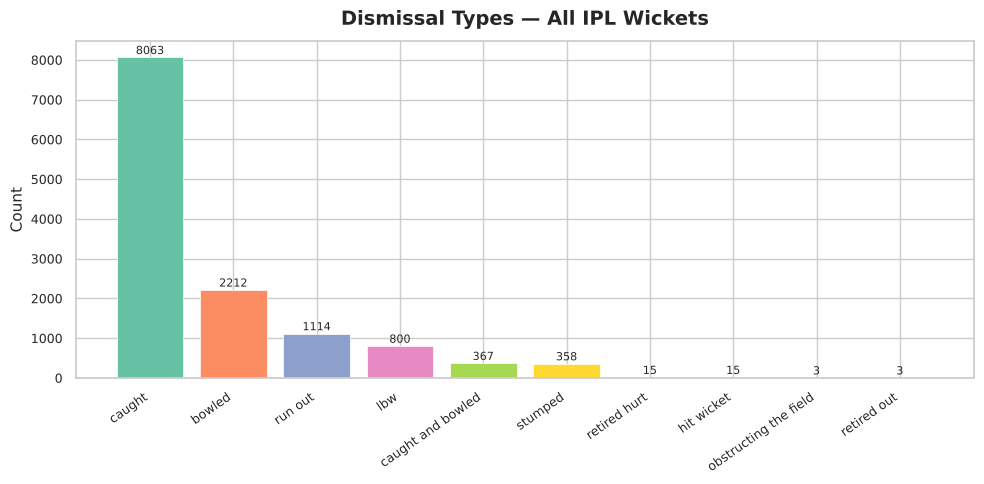

In [43]:
# Chart 10 — Dismissal type distribution
dismissals = deliveries[deliveries['is_wicket'] == 1]['dismissal_kind'].value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
colors = sns.color_palette('Set2', len(dismissals))
bars = ax.bar(dismissals.index, dismissals.values, color=colors,
              edgecolor='white', linewidth=0.5)
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 20,
            str(int(bar.get_height())),
            ha='center', va='bottom', fontsize=8)
ax.set_title('Dismissal Types — All IPL Wickets', fontsize=14, fontweight='bold', pad=12)
ax.set_ylabel('Count')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

## 13. Overview Dashboard (Plotly → dashboard_overview.html)

A static eight-panel overview of the main results. The interactive version with season and team filters is built in Section 14 (`dashboard.html`).

In [44]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

BLUE, GOLD, RED, GREEN, PURPLE = '#1a6eb5', '#f5a623', '#c0392b', '#0d7c4e', '#8e44ad'

# -- panel data (all built from variables created earlier in this notebook) --
wp           = win_pct.sort_values()                          # ascending so the best team is drawn on top
wp_wins      = wins.reindex(wp.index)
wp_matches   = total_matches.reindex(wp.index)
season_cnt   = df.groupby('season')['id'].count()
decision     = valid_matches.groupby('toss_decision')['toss_win_match_win'].agg(['mean', 'count'])
top_runs     = runs.head(10).sort_values()
top_wkts     = wickets.head(10).sort_values()
top_venues   = df['venue'].value_counts().head(10).sort_values()
season_best  = result[result['season_rank'] == 1].drop_duplicates('season')

six_venues = pd.read_sql("""
    SELECT m.venue,
           CAST(SUM(CASE WHEN d.batsman_runs = 6 THEN 1 ELSE 0 END) AS FLOAT)
               / COUNT(DISTINCT m.id) AS six_per_match
    FROM matches m
    LEFT JOIN deliveries d ON d.match_id = m.id
    GROUP BY m.venue
    HAVING COUNT(DISTINCT m.id) > 20
    ORDER BY six_per_match DESC
    LIMIT 10
""", conn).sort_values('six_per_match')

# Panels with long text labels sit in the LEFT column (outer axes resize automatically).
fig_dash = make_subplots(
    rows=4, cols=2,
    subplot_titles=[
        'Win % by team (dashed line = 50%)',
        'Matches per season',
        'Sixes per match by venue (venues with over 20 matches)',
        f'Toss winner win rate by decision (chi-square p = {p_decision:.3f})',
        'Top 10 venues by matches hosted',
        'Top 10 run scorers',
        'Top run scorer of each season',
        'Top 10 wicket takers',
    ],
    vertical_spacing=0.07, horizontal_spacing=0.14,
)

# 1,1 -- win % (not raw wins: raw wins reward teams that simply played more seasons)
fig_dash.add_trace(go.Bar(
    y=wp.index, x=wp.values, orientation='h',
    marker_color=[BLUE if v >= 50 else RED for v in wp.values],
    text=[f'{v:.1f}%' for v in wp.values], textposition='outside', cliponaxis=False,
    customdata=list(zip(wp_wins.values, wp_matches.values)),
    hovertemplate='%{y}<br>Win %: %{x:.1f}%<br>%{customdata[0]} wins in %{customdata[1]} matches<extra></extra>'),
    row=1, col=1)
fig_dash.add_vline(x=50, line_dash='dash', line_color='grey', row=1, col=1)

# 1,2 -- matches per season (bars: each season is a separate bucket)
fig_dash.add_trace(go.Bar(
    x=season_cnt.index, y=season_cnt.values, marker_color=GOLD,
    text=season_cnt.values, textposition='outside', cliponaxis=False,
    hovertemplate='%{x}: %{y} matches<extra></extra>'),
    row=1, col=2)

# 2,1 -- sixes per match by venue
fig_dash.add_trace(go.Bar(
    y=six_venues['venue'], x=six_venues['six_per_match'], orientation='h', marker_color=RED,
    text=[f'{v:.1f}' for v in six_venues['six_per_match']], textposition='outside', cliponaxis=False,
    hovertemplate='%{y}: %{x:.1f} sixes per match<extra></extra>'),
    row=2, col=1)

# 2,2 -- toss decision
fig_dash.add_trace(go.Bar(
    x=decision.index.tolist(), y=(decision['mean'] * 100).values, marker_color=[GOLD, BLUE],
    text=[f'{m * 100:.1f}%  (n={n})' for m, n in zip(decision['mean'], decision['count'])],
    textposition='outside', cliponaxis=False, hovertemplate='%{x}: %{y:.1f}%<extra></extra>'),
    row=2, col=2)
fig_dash.add_hline(y=50, line_dash='dash', line_color='grey', row=2, col=2)

# 3,1 -- venues by matches hosted (full names, no truncation)
fig_dash.add_trace(go.Bar(
    y=top_venues.index, x=top_venues.values, orientation='h', marker_color=BLUE,
    text=top_venues.values, textposition='outside', cliponaxis=False), row=3, col=1)

# 3,2 / 4,2 -- player leaderboards
fig_dash.add_trace(go.Bar(
    y=top_runs.index, x=top_runs.values, orientation='h', marker_color=RED,
    text=[f'{v:,}' for v in top_runs.values], textposition='outside', cliponaxis=False), row=3, col=2)
fig_dash.add_trace(go.Bar(
    y=top_wkts.index, x=top_wkts.values, orientation='h', marker_color=GREEN,
    text=top_wkts.values, textposition='outside', cliponaxis=False), row=4, col=2)

# 4,1 -- season-wise top scorer (SQL window-function result)
fig_dash.add_trace(go.Bar(
    x=season_best['season'], y=season_best['total_runs'], marker_color=PURPLE,
    text=season_best['batter'], textangle=-90, textposition='inside', insidetextanchor='start',
    hovertemplate='%{x}: %{text} (%{y} runs)<extra></extra>'),
    row=4, col=1)

# -- headline numbers across the top --
kpis = [(f'{len(df):,}', 'matches'), (f"{df['season'].nunique()}", 'seasons'),
        (f'{all_teams.nunique()}', 'franchises'), (f'{len(deliveries):,}', 'ball-by-ball deliveries')]
for i, (value, label) in enumerate(kpis):
    fig_dash.add_annotation(xref='paper', yref='paper', x=0.125 + i * 0.25, y=1.05,
                            text=f'<span style="font-size:26px"><b>{value}</b></span><br>{label}',
                            showarrow=False, align='center')

fig_dash.update_xaxes(range=[0, 80], row=1, col=1)           # head-room for the outside labels
fig_dash.update_yaxes(range=[0, 90], row=1, col=2)
fig_dash.update_xaxes(range=[0, 20], row=2, col=1)
fig_dash.update_yaxes(range=[0, 70], row=2, col=2, title_text='Win %')
fig_dash.update_xaxes(dtick=2, row=1, col=2)
fig_dash.update_xaxes(range=[0, 10500], row=3, col=2)
fig_dash.update_xaxes(range=[0, 240], row=4, col=2)
fig_dash.update_xaxes(range=[0, 135], row=3, col=1)
fig_dash.update_yaxes(automargin=True)
fig_dash.update_layout(
    title=dict(text='<b>IPL Data Analysis Dashboard (2008-2024)</b>', x=0.5, xanchor='center', y=0.985,
               font=dict(size=22)),
    height=1900, showlegend=False, template='plotly_white',
    margin=dict(t=190, b=40, l=40, r=40),
    paper_bgcolor='#f9f9f9', font=dict(family='Arial', size=11),
)

fig_dash.write_html('dashboard_overview.html', include_plotlyjs='cdn')
print('dashboard_overview.html saved -- open it in your browser.')
fig_dash.show()

dashboard_overview.html saved -- open it in your browser.


## 14. Power BI Data Export

Power BI should read the **same cleaned data** the notebook analysed, not re-clean the raw CSVs with different rules.  
This cell writes three analysis-ready files to `powerbi/`:

| File | Grain | Why it exists |
|------|-------|---------------|
| `matches_clean.csv` | one row per match | match-level facts; `-1` placeholders restored to real NULLs |
| `team_matches.csv` | one row per team per match | makes win % a simple `SUM / COUNT` (no DAX tricks) |
| `deliveries_clean.csv` | one row per ball | adds pre-computed flags so the DAX stays trivial |

The cell ends with reconciliation checks against numbers computed earlier in this notebook. The same files also feed the interactive dashboard (next cell), so Power BI is optional.

In [45]:
import os
os.makedirs('powerbi', exist_ok=True)

# 1) matches -- restore real NULLs where the notebook used -1 as a placeholder, add a toss flag
m_out = df.copy()
for col in ['result_margin', 'target_runs', 'target_overs']:
    m_out[col] = m_out[col].replace(-1, np.nan)
m_out['toss_winner_won'] = ((m_out['toss_winner'] == m_out['winner']).astype('Int64')
                            .where(m_out['winner'] != 'No Result'))      # NULL for no-result matches
m_out['date'] = m_out['date'].dt.strftime('%Y-%m-%d')
m_out.to_csv('powerbi/matches_clean.csv', index=False)

# 2) deliveries -- same cleaned team names, plus flags that mirror the notebook's cricket rules
d_out = deliveries.copy()
d_out['extras_type']    = d_out['extras_type'].fillna('none')
d_out['dismissal_kind'] = d_out['dismissal_kind'].fillna('none')
d_out['balls_faced']    = (d_out['extras_type'] != 'wides').astype(int)                       # wides are not faced
d_out['legal_delivery'] = (~d_out['extras_type'].isin(['wides', 'noballs'])).astype(int)      # counts toward the over
d_out['bowler_runs']    = d_out['batsman_runs'] + d_out['extra_runs'].where(
                              d_out['extras_type'].isin(['wides', 'noballs']), 0)             # byes/leg-byes not charged
d_out['bowler_wicket']  = ((d_out['is_wicket'] == 1)
                           & ~d_out['dismissal_kind'].isin(no_bowler_credit)).astype(int)     # no run-outs etc.
d_out['is_four']        = (d_out['batsman_runs'] == 4).astype(int)
d_out['is_six']         = (d_out['batsman_runs'] == 6).astype(int)
d_out.to_csv('powerbi/deliveries_clean.csv', index=False)

# 3) team_matches -- unpivot team1/team2 into one row per team per match
keep = ['id', 'season', 'date', 'match_type', 'venue', 'city', 'toss_winner', 'toss_decision',
        'winner', 'result', 'result_margin']
side_a = m_out[keep + ['team1', 'team2']].rename(columns={'team1': 'team', 'team2': 'opponent'})
side_b = m_out[keep + ['team2', 'team1']].rename(columns={'team2': 'team', 'team1': 'opponent'})
tm = pd.concat([side_a, side_b], ignore_index=True).rename(columns={'id': 'match_id'})
tm['won']       = (tm['winner'] == tm['team']).astype(int)
tm['no_result'] = (tm['winner'] == 'No Result').astype(int)
tm['lost']      = 1 - tm['won'] - tm['no_result']
tm['toss_won']  = (tm['toss_winner'] == tm['team']).astype(int)
tm.to_csv('powerbi/team_matches.csv', index=False)

# -- reconciliation: Power BI inputs must agree with the analysis above --
assert len(tm) == 2 * len(df), 'team_matches should have two rows per match'
assert (tm.groupby('team')['won'].sum().reindex(wins.index) == wins).all(), 'wins per team differ'
assert d_out.groupby('bowler')['bowler_wicket'].sum().max() == wickets.max(), 'wicket totals differ'
assert d_out.groupby('batter')['batsman_runs'].sum().max() == runs.max(), 'run totals differ'

print('matches_clean.csv    :', m_out.shape)
print('team_matches.csv     :', tm.shape)
print('deliveries_clean.csv :', d_out.shape)
print('Reconciliation checks passed.')

matches_clean.csv    : (1095, 21)
team_matches.csv     : (2190, 17)
deliveries_clean.csv : (260920, 23)
Reconciliation checks passed.


### Interactive dashboard (`dashboard.html`)

`build_dashboard.py` reads the exported tables and writes one self-contained HTML page with season-range, team and sample-size filters. Open `dashboard.html` in a browser (it loads Plotly from a CDN).

In [46]:
import subprocess, sys
subprocess.run([sys.executable, 'build_dashboard.py'], check=True)

dashboard.html written (407 KB) -- open it in your browser.


CompletedProcess(args=['/usr/bin/python3', 'build_dashboard.py'], returncode=0)

## 15. Key Findings

Each finding is written as **Finding → Interpretation → Implication**. The cell below computes the evidence for Finding 1 directly from `match_type`, so no number in the write-up comes from memory.

In [47]:
# Evidence for Finding 1: finals reached relative to seasons actually played
print(df['match_type'].value_counts(), '\n')

finals = df[df['match_type'].str.strip().str.lower() == 'final']      # exact match: 'Semi Final' must NOT count
print('Final matches found:', len(finals), '(one per season expected)\n')

finals_played = pd.concat([finals['team1'], finals['team2']]).value_counts()
titles        = finals['winner'].value_counts()

appearances = pd.concat([df[['season', 'team1']].rename(columns={'team1': 'team'}),
                         df[['season', 'team2']].rename(columns={'team2': 'team'})])
seasons_played = appearances.drop_duplicates().groupby('team')['season'].nunique()

finals_summary = pd.DataFrame({'seasons_played': seasons_played,
                               'finals_played':  finals_played,
                               'titles':         titles}).fillna(0).astype(int)
finals_summary['finals_per_season_%'] = (finals_summary['finals_played']
                                         / finals_summary['seasons_played'] * 100).round(1)
finals_summary.sort_values(['titles', 'finals_played'], ascending=False).head(8)

match_type
League                1029
Final                   17
Qualifier 1             14
Qualifier 2             14
Eliminator              11
Semi Final               6
Elimination Final        3
3rd Place Play-Off       1
Name: count, dtype: int64 

Final matches found: 17 (one per season expected)



,seasons_played,finals_played,titles,finals_per_season_%
Chennai Super Kings,15,10,5,66.70
Mumbai Indians,17,6,5,35.30
Kolkata Knight Riders,17,4,3,23.50
Sunrisers Hyderabad,12,3,1,25.00
Gujarat Titans,3,2,1,66.70
Rajasthan Royals,15,2,1,13.30
Deccan Chargers,5,1,1,20.00
Royal Challengers Bangalore,17,3,0,17.60


### Finding 1 — CSK's standing is understated by raw totals

**Finding:** Chennai Super Kings rank 2nd in both total wins (138) and win percentage (~58%), and they did it in **15 seasons**: CSK did not play in 2016 or 2017 (suspension), while Mumbai Indians, Kolkata Knight Riders and Royal Challengers Bangalore played all 17. The finals table above shows CSK reached **10 finals in 15 seasons (66.7%) and won 5 titles**; Mumbai Indians reached 6 finals in 17 seasons (35.3%) and also won 5. Rajasthan Royals served the same suspension but reached 2 finals in 15 seasons and won ~50.7% of matches.

**Interpretation:** Raw win counts reward the number of seasons played, so CSK's totals understate its rate of success. Rajasthan Royals are a natural comparison because they missed the same two seasons, so the suspension alone cannot explain CSK's position. Finals reached per season played is a stronger signal of repeated high-pressure success than win % alone, because win % treats every league match equally. Titles are level with Mumbai (5 each), but CSK got there in two fewer seasons. Gujarat Titans also show 66.7%, but over only 3 seasons, which is far weaker evidence.

**Implication:** Franchise rankings should be reported with **seasons active** and **finals per season played** next to win %, with the sample size visible. A ranking by raw wins alone would understate CSK and flatter franchises that simply played more seasons.

---

### Finding 2 — The toss does not matter, but the toss *decision* does

**Finding:** Toss winners won the match 50.8% of the time (χ² p = 0.52, not significant). Split by decision, toss winners who chose to **field** won ~53.9% and those who chose to **bat** won ~45.4% — a gap of about 8.5 percentage points (χ² p ≈ 0.009, significant at 5%).

**Interpretation:** The blended 50.8% hides two different groups. Winning the toss is not an advantage by itself; what the captain does with it is associated with a real difference in results. 64% of toss winners already choose to field, so captains broadly act as if this edge exists.

**Implication:** Treat the result as an association, not proof of cause: captains pick the option they expect to suit the conditions, and this dataset has no pitch, dew, weather or day/night field to test that. The next step is to repeat the split by venue and by season using columns already in `matches.csv`.

---

### Finding 3 — Peak performance vs repeated performance

**Finding:** In the season-wise ranking (SQL Q4), V Kohli's 973 runs in 2016 is the highest single-season total in the table, and he topped two seasons (2016, 2024). DA Warner topped three seasons (2015, 2017, 2019); CH Gayle topped two (2011, 2012).

**Interpretation:** Kohli holds the single biggest peak, while Warner holds the most seasons at the top. All-time run totals (Kohli 8,014) therefore hide how differently these players built their records.

**Implication:** Player evaluation should look at both the peak season and how often a player finishes top of their season, not only the career total.

## 16. Recommendations

1. **Compare franchises on exposure-adjusted metrics.** Report win % and finals per season played alongside raw wins, with a minimum-matches rule so small samples (e.g. Gujarat Titans, 45 matches) are not ranked as if they were settled.
2. **Evaluate toss decisions at venue level.** The field-first advantage is significant overall, but the dataset cannot say *why*; split it by venue and season before using it as a rule.
3. **Value batters on runs and strike rate together.** High-strike-rate players such as AD Russell (~174.8 SR, min. 1,000 balls) score fast without topping the run charts, so the two measures answer different questions.

## 17. Conclusions & Insights

### Team Performance
| Finding | Detail |
|---------|--------|
| Most wins (raw count) | **Mumbai Indians** — 144 wins, most in IPL history |
| Best win % (all-time) | **Gujarat Titans** — ~62%, but played fewer seasons |
| Best win % (legacy team) | **Chennai Super Kings** — ~58%, across 15 seasons (no 2016-17) |
| Worst win % | **Pune Warriors** — ~26%, the most one-sided record |

### Toss Analysis
| Finding | Detail |
|---------|--------|
| Toss converts to win | ~50.8% — barely above random chance |
| Better toss decision | **Field first**: ~53.9% win rate vs **Bat first**: ~45.4% |
| Captain preference | 64% of toss winners choose to field (chase is preferred strategy) |
| Toss win → match win (chi-square) | **p = 0.52** — not significant; winning the toss alone is not a reliable predictor |
| Decision effect: field vs bat (chi-square) | **p ≈ 0.009** — significant; field-first toss winners win ~8.5 percentage points more often |

### Player Records
| Stat | Player | Value |
|------|--------|-------|
| Most runs (all-time) | V Kohli | 8,014 runs |
| Highest strike rate (≥1000 balls) | AD Russell | ~174.8 SR |
| Most wickets (all-time) | YS Chahal | 205 wickets |

### Venue Insights
| Finding | Detail |
|---------|--------|
| Most matches hosted | Wankhede Stadium, Mumbai — 118 matches |
| Highest sixes/match | M Chinnaswamy Stadium, Bangalore — 14.9 sixes/match |

### Season Trends
- Match volume peaked in **2011–2013** (73–76 matches) with 9–10 teams, then stabilised at ~60 for the 8-team format.
- The 2022 expansion (adding GT and LSG) pushed counts back up to 74.

---

**Analyst note:** Winning the toss does not predict the result (p = 0.52), but *what the toss winner decides* does: choosing to field is associated with a higher win rate (p ≈ 0.009, see Section 11).  
This is an association, not proof of cause — captains choose according to conditions this dataset does not record (pitch, dew, day/night). Match outcome is still largely decided by player performance on the day.


In [48]:
conn.close()
print('SQLite connection closed. Analysis complete.')

SQLite connection closed. Analysis complete.
